Bài thực hành 1. Hàm mục tiêu một biến

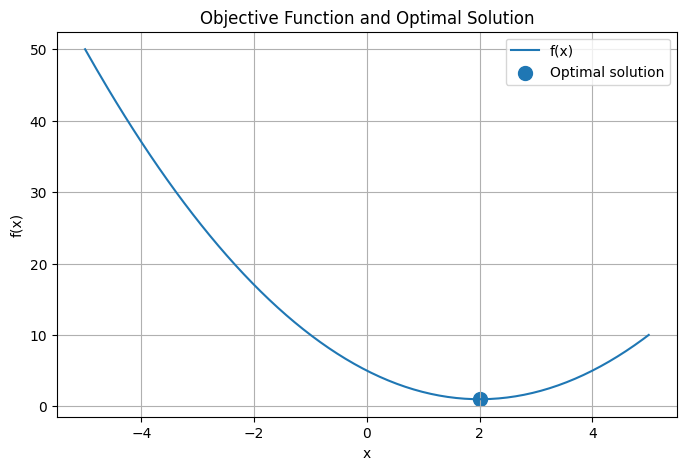

In [140]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
x = np.linspace(-5, 5, 200)
f = (x - 2)**2 + 1
x_opt = 2
f_opt = 1
plt.figure(figsize=(8, 5))
plt.plot(x, f, label="f(x)")
plt.scatter(x_opt, f_opt, s=100, label="Optimal solution")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Objective Function and Optimal Solution")
plt.grid(True)
plt.legend()
plt.show()

Bài thực hành 2. Hàm mục tiêu hai biến
f(x,y) = (x - 1)² + 2(y + 2)²

In [141]:
x = np.linspace(-5, 5, 200)
y = np.linspace(-6, 2, 200)
X, Y = np.meshgrid(x, y)
Z = (X - 1)**2 + 2*(Y + 2)**2

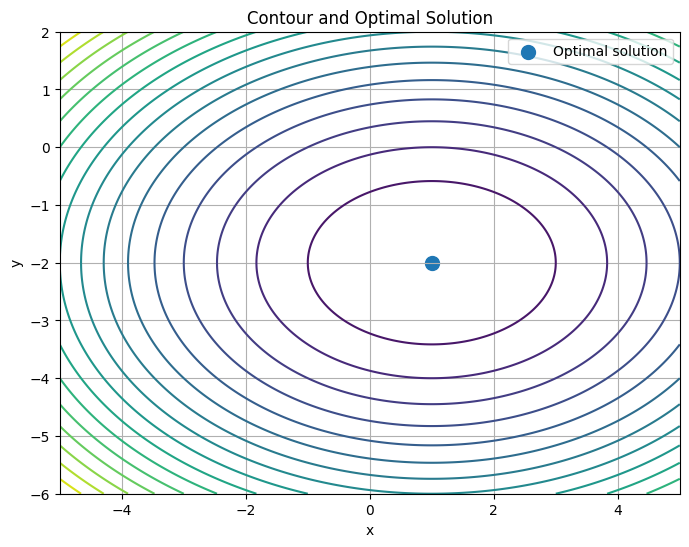

In [142]:
plt.figure(figsize=(8, 6))
contour = plt.contour(X, Y, Z, levels=20)
plt.scatter(1, -2, s=100, label="Optimal solution")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Contour and Optimal Solution")
plt.grid(True)
plt.legend()
plt.show()

Bài thực hành 3. Mô hình hóa bài toán phân bổ GPU

In [143]:

# Tạo bảng mô hình
data = {
    "Thành phần": [
        "Biến quyết định", "Biến quyết định","Objective","Constraint","Constraint","Constraint"],
    "Biểu diễn": [
        "x_A","x_B", "5x_A + 8x_B", "x_A + x_B ≤ 8","x_A, x_B ≥ 0","x_A, x_B ∈ Z"],
    "Ý nghĩa": [
        "Số GPU cấp cho Job A","Số GPU cấp cho Job B","Tổng hiệu năng", "Tổng GPU tối đa", "Không cấp số GPU âm","GPU là số nguyên"]}
df = pd.DataFrame(data)
# Tìm nghiệm tối ưu
best_value = -1
best_xA = 0
best_xB = 0
for x_A in range(9):
    for x_B in range(9):
        if x_A + x_B <= 8:
            P = 5 * x_A + 8 * x_B
            if P > best_value:
                best_value = P
                best_xA = x_A
                best_xB = x_B
# In bảng
print(df.to_string(index=False))
print("\nKẾT QUẢ TỐI ƯU")
print("x_A =", best_xA)
print("x_B =", best_xB)
print("P tối đa =", best_value)

     Thành phần     Biểu diễn              Ý nghĩa
Biến quyết định           x_A Số GPU cấp cho Job A
Biến quyết định           x_B Số GPU cấp cho Job B
      Objective   5x_A + 8x_B       Tổng hiệu năng
     Constraint x_A + x_B ≤ 8      Tổng GPU tối đa
     Constraint  x_A, x_B ≥ 0  Không cấp số GPU âm
     Constraint  x_A, x_B ∈ Z     GPU là số nguyên

KẾT QUẢ TỐI ƯU
x_A = 0
x_B = 8
P tối đa = 64


Bài thực hành 4. Giải bài toán GPU bằng Brute Force


In [144]:
feasible_solutions = []
for x_A in range(9):
 for x_B in range(9):
  if x_A + x_B <= 8:
    performance = 5*x_A + 8*x_B
    feasible_solutions.append((x_A, x_B, performance))
print("x_A | x_B | Performance")
for solution in feasible_solutions:
 print(solution)
best_solution = None
best_value = -np.inf
for x_A in range(9):
 for x_B in range(9):
  if x_A + x_B <= 8:
    performance = 5*x_A + 8*x_B
  if performance > best_value:
    best_value = performance
    best_solution = (x_A, x_B)
print("Best solution:", best_solution)
print("Best objective:", best_value)

x_A | x_B | Performance
(0, 0, 0)
(0, 1, 8)
(0, 2, 16)
(0, 3, 24)
(0, 4, 32)
(0, 5, 40)
(0, 6, 48)
(0, 7, 56)
(0, 8, 64)
(1, 0, 5)
(1, 1, 13)
(1, 2, 21)
(1, 3, 29)
(1, 4, 37)
(1, 5, 45)
(1, 6, 53)
(1, 7, 61)
(2, 0, 10)
(2, 1, 18)
(2, 2, 26)
(2, 3, 34)
(2, 4, 42)
(2, 5, 50)
(2, 6, 58)
(3, 0, 15)
(3, 1, 23)
(3, 2, 31)
(3, 3, 39)
(3, 4, 47)
(3, 5, 55)
(4, 0, 20)
(4, 1, 28)
(4, 2, 36)
(4, 3, 44)
(4, 4, 52)
(5, 0, 25)
(5, 1, 33)
(5, 2, 41)
(5, 3, 49)
(6, 0, 30)
(6, 1, 38)
(6, 2, 46)
(7, 0, 35)
(7, 1, 43)
(8, 0, 40)
Best solution: (0, 8)
Best objective: 64


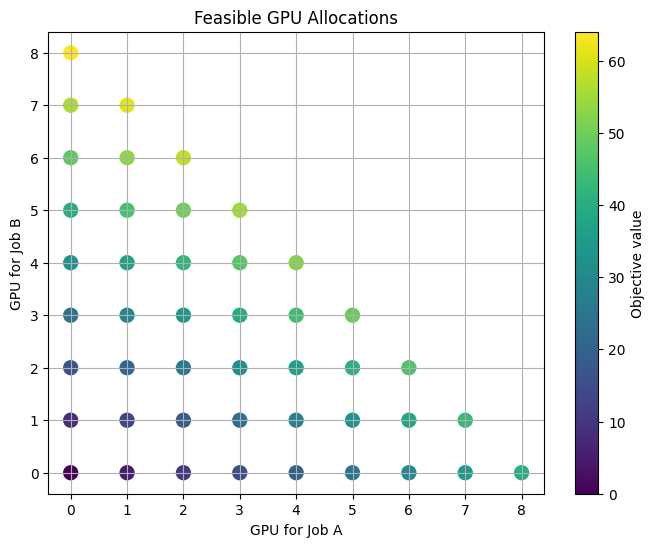

In [145]:
XA = []
XB = []
P = []
for x_A, x_B, performance in feasible_solutions:
 XA.append(x_A)
 XB.append(x_B)
 P.append(performance)
plt.figure(figsize=(8, 6))
scatter = plt.scatter(XA, XB, c=P, s=100)
plt.colorbar(scatter, label="Objective value")
plt.xlabel("GPU for Job A")
plt.ylabel("GPU for Job B")
plt.title("Feasible GPU Allocations")
plt.grid(True)
plt.show()

Bài tập

Bài 1. Hàm mục tiêu một biến không lồi – Grid Search và độ phân giả

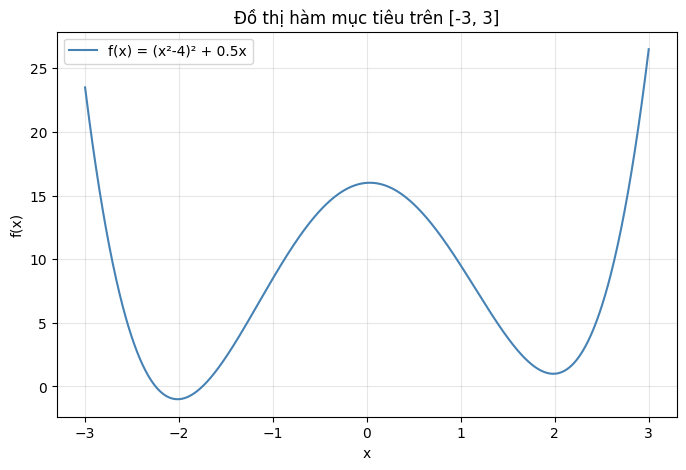

f''(x) = 12x² - 16 đổi dấu tại x ≈ ±1.1547
=> Với |x| < 1.1547, f''(x) < 0 (hàm lõm/không lồi tại đó).
=> Vậy f(x) KHÔNG lồi trên toàn miền [-3, 3] (có 1 đoạn lõm ở giữa,
   dẫn đến 2 cực tiểu địa phương đối xứng, không phải 1 cực tiểu toàn cục duy nhất kiểu lồi).


In [146]:
def f(x):
    return (x**2 - 4)**2 + 0.5*x
# Vẽ đồ thị với 1000 điểm (> 600 theo yêu cầu)
x_plot = np.linspace(-3, 3, 1000)
y_plot = f(x_plot)
plt.figure(figsize=(8, 5))
plt.plot(x_plot, y_plot, color='steelblue', label='f(x) = (x²-4)² + 0.5x')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title('Đồ thị hàm mục tiêu trên [-3, 3]')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()
# Nhận xét tính lồi bằng đạo hàm bậc 2
# f''(x) = 12x^2 - 16, đổi dấu tại x = ±sqrt(16/12) ≈ ±1.1547
x_infl = np.sqrt(16/12)
print(f"f''(x) = 12x² - 16 đổi dấu tại x ≈ ±{x_infl:.4f}")
print("=> Với |x| < 1.1547, f''(x) < 0 (hàm lõm/không lồi tại đó).")
print("=> Vậy f(x) KHÔNG lồi trên toàn miền [-3, 3] (có 1 đoạn lõm ở giữa,")
print("   dẫn đến 2 cực tiểu địa phương đối xứng, không phải 1 cực tiểu toàn cục duy nhất kiểu lồi).")

In [147]:
def grid_search(f, a, b, step):
    start = time.perf_counter()
    x_grid = np.arange(a, b + step/2, step)  # +step/2 để chắc chắn lấy được điểm cuối b
    f_vals = f(x_grid)
    idx_min = np.argmin(f_vals)
    x_hat = x_grid[idx_min]
    f_hat = f_vals[idx_min]
    elapsed = time.perf_counter() - start
    n_evals = len(x_grid)
    return x_hat, f_hat, n_evals, elapsed

In [148]:
steps = [0.5, 0.1, 0.01]
results = []

for dx in steps:
    x_hat, f_hat, n_evals, elapsed = grid_search(f, -3, 3, dx)
    results.append({
        'Δx': dx,
        'Số lần đánh giá hàm': n_evals,
        'x̂': x_hat,
        'f(x̂)': f_hat,
        'Runtime (s)': elapsed
    })

df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))

  Δx  Số lần đánh giá hàm    x̂     f(x̂)  Runtime (s)
0.50                   13 -2.00 -1.000000     0.001514
0.10                   61 -2.00 -1.000000     0.000754
0.01                  601 -2.02 -1.003536     0.000067


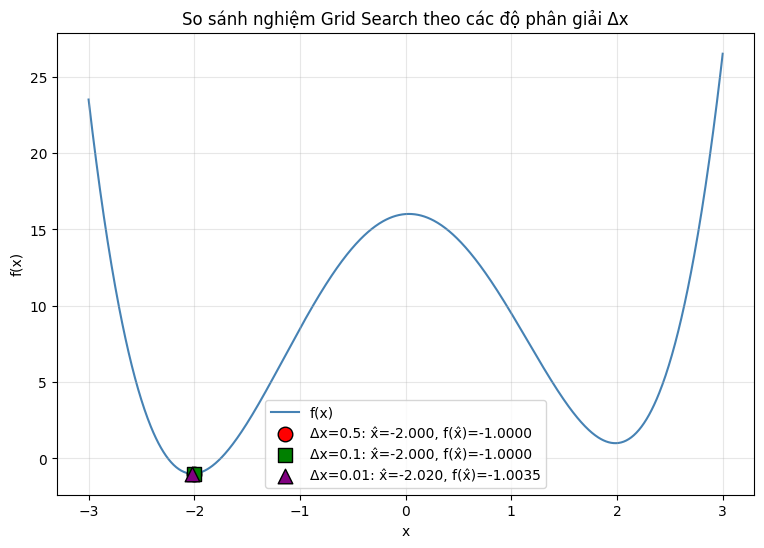


Nghiệm tốt nhất tổng thể: Δx=0.01, x̂=-2.0200, f(x̂)=-1.003536


In [149]:
plt.figure(figsize=(9, 6))
plt.plot(x_plot, y_plot, color='steelblue', label='f(x)', zorder=1)
colors = ['red', 'green', 'purple']
markers = ['o', 's', '^']
for res, color, marker in zip(results, colors, markers):
    plt.scatter(res['x̂'], res['f(x̂)'], color=color, marker=marker, s=110,
                edgecolors='black', zorder=5,
                label=f"Δx={res['Δx']}: x̂={res['x̂']:.3f}, f(x̂)={res['f(x̂)']:.4f}")
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title('So sánh nghiệm Grid Search theo các độ phân giải Δx')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

best_overall = min(results, key=lambda r: r['f(x̂)'])
print(f"\nNghiệm tốt nhất tổng thể: Δx={best_overall['Δx']}, "
      f"x̂={best_overall['x̂']:.4f}, f(x̂)={best_overall['f(x̂)']:.6f}")

Bài 2

In [150]:
# Miền khảo sát: chọn vùng bao quanh điểm tối ưu (2,1)
x = np.linspace(-2, 6, 400)
y = np.linspace(-4, 6, 400)
X, Y = np.meshgrid(x, y)
def f(x, y):
    return 2*(x - 2)**2 + (y - 1)**2
Z = f(X, Y)

In [151]:
# f(x,y) = 2(x-2)^2 + (y-1)^2
# df/dx = 4(x-2) = 0  =>  x = 2
# df/dy = 2(y-1) = 0  =>  y = 1
# f là tổng bình phương (dạng bowl lồi) nên (2,1) là cực tiểu toàn cục, không phải cực trị địa phương

x_opt, y_opt = 2, 1
f_opt = f(x_opt, y_opt)
print(f"Nghiệm tối ưu (phân tích): x = {x_opt}, y = {y_opt}, f(x,y) = {f_opt}")

Nghiệm tối ưu (phân tích): x = 2, y = 1, f(x,y) = 0


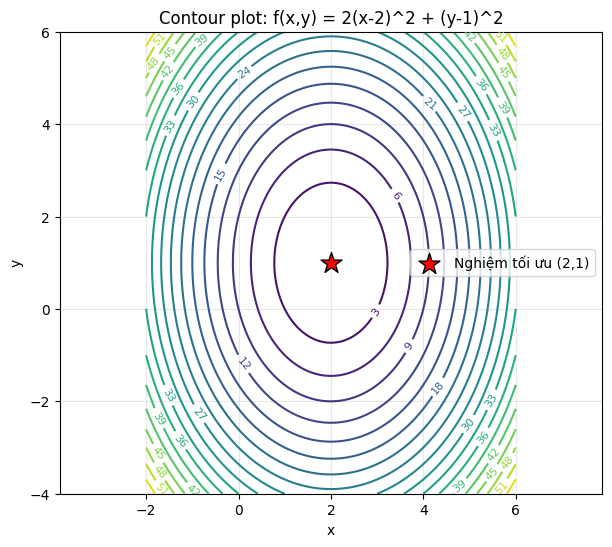

In [152]:
plt.figure(figsize=(7, 6))
cs = plt.contour(X, Y, Z, levels=20, cmap='viridis')
plt.clabel(cs, inline=True, fontsize=8)
plt.scatter(x_opt, y_opt, color='red', marker='*', s=250,
            edgecolors='black', zorder=5, label=f'Nghiệm tối ưu ({x_opt},{y_opt})')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Contour plot: f(x,y) = 2(x-2)^2 + (y-1)^2')
plt.legend()
plt.axis('equal')
plt.grid(alpha=0.3)
plt.show()

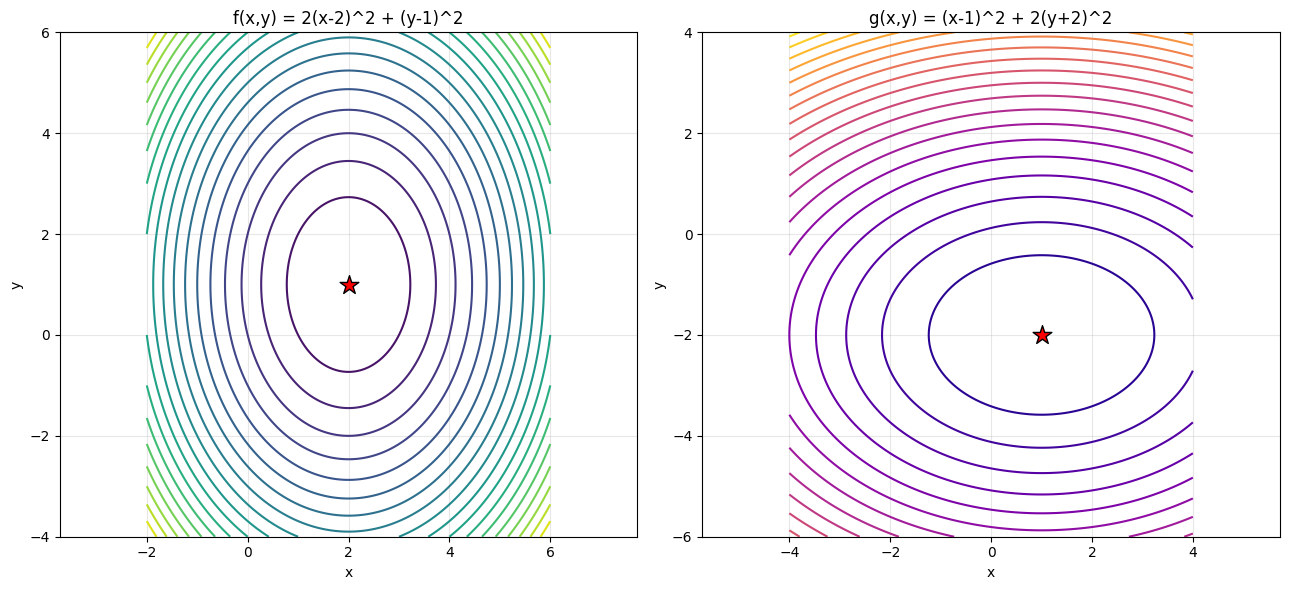

In [153]:
def g(x, y):
    return (x - 1)**2 + 2*(y + 2)**2

x2 = np.linspace(-4, 4, 400)
y2 = np.linspace(-6, 4, 400)
X2, Y2 = np.meshgrid(x2, y2)
Zg = g(X2, Y2)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

cs1 = axes[0].contour(X, Y, Z, levels=20, cmap='viridis')
axes[0].scatter(2, 1, color='red', marker='*', s=200, edgecolors='black', zorder=5)
axes[0].set_title('f(x,y) = 2(x-2)^2 + (y-1)^2')
axes[0].set_xlabel('x'); axes[0].set_ylabel('y')
axes[0].axis('equal'); axes[0].grid(alpha=0.3)

cs2 = axes[1].contour(X2, Y2, Zg, levels=20, cmap='plasma')
axes[1].scatter(1, -2, color='red', marker='*', s=200, edgecolors='black', zorder=5)
axes[1].set_title('g(x,y) = (x-1)^2 + 2(y+2)^2')
axes[1].set_xlabel('x'); axes[1].set_ylabel('y')
axes[1].axis('equal'); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Bài 3

In [154]:
feasible_solutions = []
# Duyệt toàn bộ không gian nghiệm nguyên trong giới hạn hợp lý
for x_A in range(2, 13):        # x_A >= 2
    for x_B in range(1, 13):    # x_B >= 1
        for x_C in range(0, 13):  # x_C >= 0
            if x_A + x_B + x_C <= 12:  # ràng buộc tổng GPU
                Z = 5*x_A + 8*x_B + 6*x_C
                feasible_solutions.append({
                    'x_A': x_A, 'x_B': x_B, 'x_C': x_C,
                    'Tổng GPU': x_A + x_B + x_C,
                    'Z (hiệu năng)': Z
                })

df = pd.DataFrame(feasible_solutions)
print(f"Số nghiệm khả thi: {len(df)}")
df.head(10)

Số nghiệm khả thi: 220


,x_A,x_B,x_C,Tổng GPU,Z (hiệu năng)
0,2,1,0,3,18
1,2,1,1,4,24
2,2,1,2,5,30
3,2,1,3,6,36
4,2,1,4,7,42
5,2,1,5,8,48
6,2,1,6,9,54
7,2,1,7,10,60
8,2,1,8,11,66
9,2,1,9,12,72


In [155]:
best = df.loc[df['Z (hiệu năng)'].idxmax()]
print("Nghiệm tối ưu:")
print(f"  x_A = {int(best['x_A'])}, x_B = {int(best['x_B'])}, x_C = {int(best['x_C'])}")
print(f"  Tổng GPU sử dụng = {int(best['Tổng GPU'])}")
print(f"  Z tối ưu (hiệu năng cao nhất) = {int(best['Z (hiệu năng)'])}")

# Hiển thị top 5 nghiệm tốt nhất
print("\nTop 5 nghiệm tốt nhất:")
print(df.sort_values('Z (hiệu năng)', ascending=False).head(5).to_string(index=False))

Nghiệm tối ưu:
  x_A = 2, x_B = 10, x_C = 0
  Tổng GPU sử dụng = 12
  Z tối ưu (hiệu năng cao nhất) = 90

Top 5 nghiệm tốt nhất:
 x_A  x_B  x_C  Tổng GPU  Z (hiệu năng)
   2   10    0        12             90
   2    9    1        12             88
   3    9    0        12             87
   2    8    2        12             86
   3    8    1        12             85


In [156]:
print(f"Tổng số nghiệm khả thi (thỏa mãn tất cả ràng buộc): {len(df)}")

Tổng số nghiệm khả thi (thỏa mãn tất cả ràng buộc): 220


Bài 4

In [157]:
n_values = [1, 2, 3, 5, 8, 10]
n_combinations = [10**n for n in n_values]
df = pd.DataFrame({
    'Số biến n': n_values,
    'Số tổ hợp 10^n': n_combinations
})

# Định dạng số cho dễ đọc (dùng dấu phẩy phân cách hàng nghìn)
df['Số tổ hợp 10^n (định dạng)'] = df['Số tổ hợp 10^n'].apply(lambda x: f"{x:,}")
print(df[['Số biến n', 'Số tổ hợp 10^n (định dạng)']].to_string(index=False))

 Số biến n Số tổ hợp 10^n (định dạng)
         1                         10
         2                        100
         3                      1,000
         5                    100,000
         8                100,000,000
        10             10,000,000,000


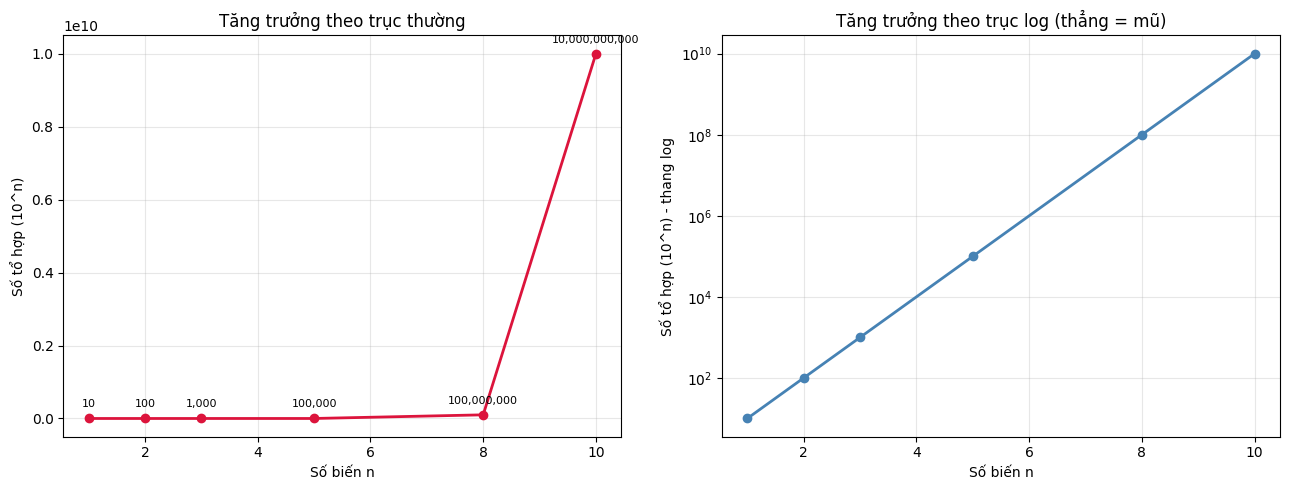

In [158]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
# Đồ thị trục thường - cho thấy độ dốc "bùng nổ"
axes[0].plot(n_values, n_combinations, marker='o', color='crimson', linewidth=2)
axes[0].set_xlabel('Số biến n')
axes[0].set_ylabel('Số tổ hợp (10^n)')
axes[0].set_title('Tăng trưởng theo trục thường')
axes[0].grid(alpha=0.3)
for x, y in zip(n_values, n_combinations):
    axes[0].annotate(f'{y:,}', (x, y), textcoords="offset points", xytext=(0,8), fontsize=8, ha='center')
# Đồ thị trục log - cho thấy đây là đường thẳng (bằng chứng của tăng trưởng mũ)
axes[1].plot(n_values, n_combinations, marker='o', color='steelblue', linewidth=2)
axes[1].set_yscale('log')
axes[1].set_xlabel('Số biến n')
axes[1].set_ylabel('Số tổ hợp (10^n) - thang log')
axes[1].set_title('Tăng trưởng theo trục log (thẳng = mũ)')
axes[1].grid(alpha=0.3, which='both')
plt.tight_layout()
plt.show()